# Résultats

In [104]:
import os
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

os.add_dll_directory(r"C:\mingw64\bin")
from pricer_module import MonteCarloPricer, OptionCallEurope

## Paramètres

In [2]:
T = 1
strike = 100
spot = 100
r = 0.05
sigma = 0.2

## Conteneur pour les résultats de simulations

In [27]:
class MonteCarloResults:
    nb_simulations: list[int]
    estimated_values: list[float]
    lower_bounds: list[float]
    upper_bounds: list[float]

    def __init__(self):
        self.nb_simulations = []
        self.estimated_values = []
        self.lower_bounds = []
        self.upper_bounds = []   

    def __repr__(self):
        return "".join(
            (
            "nb_simulations : ",
            repr(self.nb_simulations),
            "\n",
            "estimated_values : ",
            repr(self.estimated_values),
            "\n",
            "lower bounds : ",
            repr(self.lower_bounds),
            "\n",
            "upper bounds : ",
            repr(self.upper_bounds)
            )
        )

    def to_numpy(self):
        for attr in self.__dict__:
            setattr(self, attr, np.array(getattr(self, attr)))

## Convergence de la méthode de Monte-Carlo

In [ ]:
def simulate_v1(k_max):

    results = MonteCarloResults()
    option = OptionCallEurope(T=T, strike=strike)
    for k in range(2, k_max):
        N = 10**k
        pricer = MonteCarloPricer(N=N)
        result = pricer.price_v1(
            option=option,
            spot=spot,
            r=r,
            sigma=sigma
        )
        results.nb_simulations.append(N)
        results.estimated_values.append(result.estimated_value)
        results.lower_bounds.append(result.lower_bound)
        results.upper_bounds.append(result.upper_bound)
    results.to_numpy()
    return results

In [ ]:
results = simulate_v1(k_max=9)

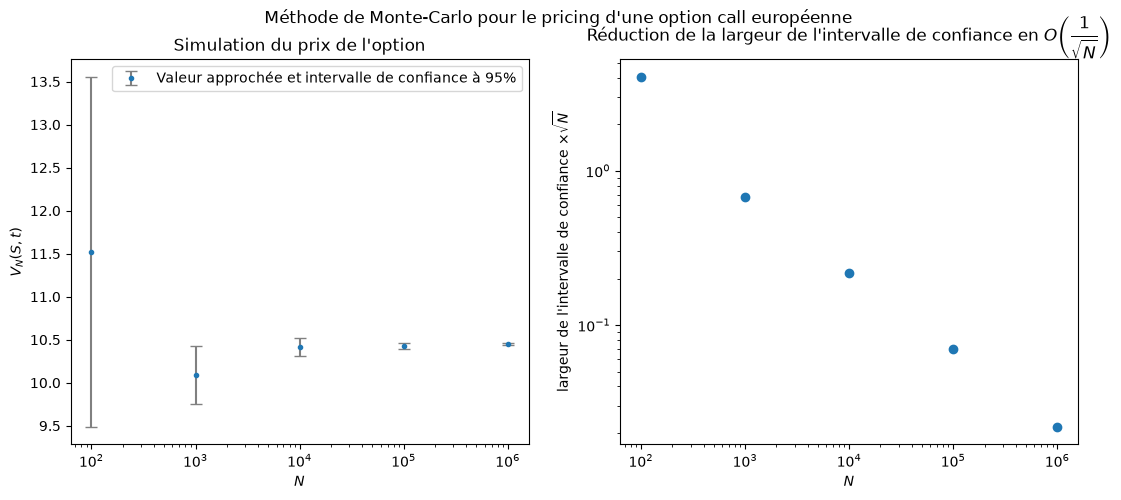

In [ ]:
fig, axs = plt.subplots(1, 2)
fig.set_size_inches(13, 5)

fig.suptitle("Méthode de Monte-Carlo pour le pricing d'une option call européenne")

axs[0].set_title("Simulation du prix de l'option")
axs[0].set_xlabel("$N$")
axs[0].set_ylabel("$V_N(S, t)$")

axs[0].set_xscale("log")
axs[0].errorbar(
    results.nb_simulations,
    results.estimated_values,
    yerr=[results.estimated_values - results.lower_bounds, results.upper_bounds - results.estimated_values],
    fmt="o",
    ecolor="gray",
    capsize=4,
    markersize=3,
    label=r"Valeur approchée et intervalle de confiance à 95%",
)
axs[0].legend()

axs[1].set_title(r"Réduction de la largeur de l'intervalle de confiance en $O\left(\dfrac{1}{\sqrt{N}}\right)$")

axs[1].scatter(
    results.nb_simulations,
    results.upper_bounds - results.lower_bounds,
)

axs[1].set_ylabel(r"largeur de l'intervalle de confiance $\times \sqrt{N}$")
axs[1].set_xscale("log")
axs[1].set_yscale("log")

axs[1].set_xlabel("$N$")

fig.savefig(Path('.')/"output"/"simulation.png", dpi=300)

plt.show()

# Réduction de variance

In [82]:
def compare_MC_methods(k_max):

    option = OptionCallEurope(T=T, strike=strike)
    comparison = {}
    for method_name in ["price_v1", "price_v2", "price_v3", "price_v4"]:
        results = MonteCarloResults()
        for k in range(2, k_max):
            N = 10**k
            pricer = MonteCarloPricer(N=N)
            method = getattr(pricer, method_name)
            kwargs = {
                "option": option,
                "spot": spot,
                "r": r,
                "sigma": sigma
            }
            if method_name == "price_v4":
                kwargs["n"] = int(0.05*N + 1)
            result = method(**kwargs)
            results.nb_simulations.append(N)
            results.estimated_values.append(result.estimated_value)
            results.lower_bounds.append(result.lower_bound)
            results.upper_bounds.append(result.upper_bound)
        results.to_numpy()
        comparison[method_name] = results
    return comparison

In [96]:
comparison = compare_MC_methods(k_max=7)

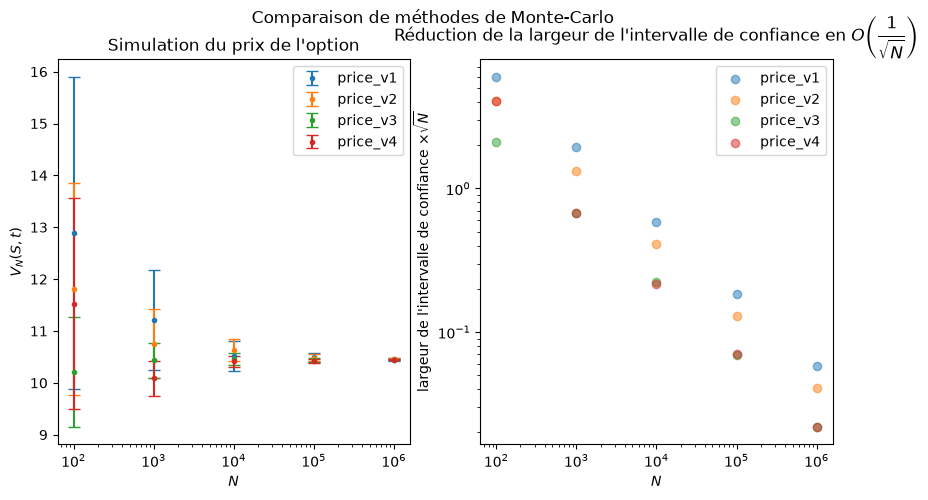

In [107]:
fig, axs = plt.subplots(1,2)
fig.set_size_inches(10, 5)

fig.suptitle("Comparaison de méthodes de Monte-Carlo")

axs[0].set_title("Simulation du prix de l'option")
axs[0].set_xlabel("$N$")
axs[0].set_ylabel("$V_N(S, t)$")

axs[0].set_xscale("log")

colors = plt.cm.tab10.colors

for (method_name, results), color in zip(comparison.items(), colors):
    axs[0].errorbar(
        results.nb_simulations,
        results.estimated_values,
        yerr=[results.estimated_values - results.lower_bounds, results.upper_bounds - results.estimated_values],
        fmt="o",
        color=color,
        ecolor=color,
        capsize=4,
        markersize=3,
        label=method_name,
    )
axs[0].legend()

axs[1].set_title(r"Réduction de la largeur de l'intervalle de confiance en $O\left(\dfrac{1}{\sqrt{N}}\right)$")

for (method_name, results), color in zip(comparison.items(), colors):
    axs[1].scatter(
        results.nb_simulations,
        results.upper_bounds - results.lower_bounds,
        color=color,
        label=method_name,
        alpha=0.5
    )

axs[1].legend()

axs[1].set_ylabel(r"largeur de l'intervalle de confiance $\times \sqrt{N}$")
axs[1].set_xscale("log")
axs[1].set_yscale("log")

axs[1].set_xlabel("$N$")

fig.savefig(Path('.')/"output"/"comparison.png", dpi=300)

plt.show()